In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")


print("All libraries imported successfully!")

In [ ]:
# ==========================================
# PROJECT DIRECTORY CONFIGURATION
# ==========================================

from pathlib import Path

PROJECT_DIR = Path.cwd().parents[1]

FAULT_DIR = PROJECT_DIR / "fault"
DATA_DIR = FAULT_DIR / "data"
OUTPUT_DIR = FAULT_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Project directories configured successfully!")
print("Project:", PROJECT_DIR)
print("Data:", DATA_DIR)
print("Output:", OUTPUT_DIR)

In [2]:
# ==========================================
# FIND ORIGINAL PUMP DATASET
# ==========================================

from pathlib import Path

# Find the main project directory
CURRENT_DIR = Path.cwd()

possible_roots = [CURRENT_DIR, *CURRENT_DIR.parents]

PROJECT_DIR = next(
    (path for path in possible_roots
     if (path / "fault").is_dir()),
    None
)

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Could not find the machine-learning project folder."
    )

# Configure directories
FAULT_DIR = PROJECT_DIR / "fault"
DATA_DIR = FAULT_DIR / "data"
OUTPUT_DIR = FAULT_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Search for CSV files
csv_files = list(DATA_DIR.glob("*.csv"))

print("=" * 50)
print("PUMP DATASET SEARCH")
print("=" * 50)

print("Project:", PROJECT_DIR)
print("Dataset folder:", DATA_DIR)

if csv_files:
    print("\nCSV datasets found:")

    for index, file in enumerate(csv_files, start=1):
        print(f"{index}. {file.name}")

else:
    print("\nNo CSV dataset found.")
    print("Place your original dataset inside fault/data.")

PUMP DATASET SEARCH
Project: d:\ml asignment\machine-learning
Dataset folder: d:\ml asignment\machine-learning\fault\data

No CSV dataset found.
Place your original dataset inside fault/data.


In [23]:
# ==========================================
# LOAD ORIGINAL PUMP DATASET
# ==========================================

from pathlib import Path
import pandas as pd

# Specify the downloaded dataset
DATA_FILE = DATA_DIR / "sensor.csv"

if DATA_FILE.exists():

    # Load CSV dataset
    df = pd.read_csv(DATA_FILE)

    print("Dataset loaded successfully!")
    print("=" * 50)

    print("Dataset name:", DATA_FILE.name)
    print("Total rows:", df.shape[0])
    print("Total columns:", df.shape[1])

    print("\nFirst five records:")
    display(df.head())

else:

    df = None

    print("Dataset not found!")
    print("Expected location:", DATA_FILE)
    print("Please put sensor.csv inside fault/data.")

Dataset loaded successfully!
Dataset name: sensor.csv
Total rows: 220320
Total columns: 55

First five records:


,Unnamed: 0,timestamp,sensor_00,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,...,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,machine_status
0,0,2018-04-01 00:00:00,2.465394,47.09201,53.2118,46.310760,634.3750,76.45975,13.41146,16.13136,...,41.92708,39.641200,65.68287,50.92593,38.194440,157.9861,67.70834,243.0556,201.3889,NORMAL
1,1,2018-04-01 00:01:00,2.465394,47.09201,53.2118,46.310760,634.3750,76.45975,13.41146,16.13136,...,41.92708,39.641200,65.68287,50.92593,38.194440,157.9861,67.70834,243.0556,201.3889,NORMAL
2,2,2018-04-01 00:02:00,2.444734,47.35243,53.2118,46.397570,638.8889,73.54598,13.32465,16.03733,...,41.66666,39.351852,65.39352,51.21528,38.194443,155.9606,67.12963,241.3194,203.7037,NORMAL
3,3,2018-04-01 00:03:00,2.460474,47.09201,53.1684,46.397568,628.1250,76.98898,13.31742,16.24711,...,40.88541,39.062500,64.81481,51.21528,38.194440,155.9606,66.84028,240.4514,203.1250,NORMAL
4,4,2018-04-01 00:04:00,2.445718,47.13541,53.2118,46.397568,636.4583,76.58897,13.35359,16.21094,...,41.40625,38.773150,65.10416,51.79398,38.773150,158.2755,66.55093,242.1875,201.3889,NORMAL


In [24]:
# ==========================================
# MISSING VALUES INSPECTION
# ==========================================

if df is not None:

    print("=" * 50)
    print("MISSING VALUES ANALYSIS")
    print("=" * 50)

    missing_values = df.isnull().sum()

    missing_report = pd.DataFrame({
        "Missing Values": missing_values,
        "Missing Percentage": (missing_values / len(df)) * 100
    })

    missing_report = missing_report.sort_values(
        by="Missing Percentage",
        ascending=False
    )

    display(missing_report)

    print("\nTotal missing values:", missing_values.sum())

else:
    print("Load the original dataset first.")

MISSING VALUES ANALYSIS


,Missing Values,Missing Percentage
sensor_15,220320,100.000000
sensor_50,77017,34.956881
sensor_51,15383,6.982117
sensor_00,10208,4.633261
sensor_07,5451,2.474129
sensor_08,5107,2.317992
sensor_06,4798,2.177741
sensor_09,4595,2.085603
sensor_01,369,0.167484
sensor_30,261,0.118464



Total missing values: 344574


In [4]:
# ==========================================
# DATASET STRUCTURE INSPECTION
# ==========================================

if df is not None:

    print("=" * 50)
    print("DATASET STRUCTURE")
    print("=" * 50)

    # Dataset dimensions
    print("\n1. Dataset Shape:")
    print(df.shape)

    # Column names
    print("\n2. Dataset Columns:")
    for column in df.columns:
        print("-", column)

    # Data types
    print("\n3. Data Types:")
    display(df.dtypes.to_frame(name="Data Type"))

    # Information about dataset
    print("\n4. Dataset Information:")
    df.info()

else:
    print("Load the original dataset first.")

Load the original dataset first.


In [5]:
# ==========================================
# STATISTICAL ANALYSIS
# ==========================================

if df is not None:

    print("STATISTICAL SUMMARY")

    display(df.describe())

else:
    print("Dataset not loaded.")

Dataset not loaded.


In [25]:
# ==========================================
# MISSING VALUE ANALYSIS
# ==========================================

if df is not None:

    missing_values = df.isnull().sum()

    missing_percentage = (
        df.isnull().sum() / len(df) * 100
    )

    missing_report = pd.DataFrame({
        "Missing Values": missing_values,
        "Missing Percentage": missing_percentage
    })

    display(missing_report)

    print(
        "\nTotal missing values:",
        df.isnull().sum().sum()
    )

else:
    print("Dataset not loaded.")

,Missing Values,Missing Percentage
Unnamed: 0,0,0.000000
timestamp,0,0.000000
sensor_00,10208,4.633261
sensor_01,369,0.167484
sensor_02,19,0.008624
sensor_03,19,0.008624
sensor_04,19,0.008624
sensor_05,19,0.008624
sensor_06,4798,2.177741
sensor_07,5451,2.474129



Total missing values: 344574


In [26]:
# ==========================================
# DUPLICATE RECORDS INSPECTION
# ==========================================

if df is not None:

    print("=" * 50)
    print("DUPLICATE RECORDS ANALYSIS")
    print("=" * 50)

    # Count duplicate rows
    duplicate_count = df.duplicated().sum()

    print("\n1. Total duplicate rows:")
    print(duplicate_count)

    # Calculate duplicate percentage
    duplicate_percentage = (duplicate_count / len(df)) * 100

    print("\n2. Duplicate percentage:")
    print(f"{duplicate_percentage:.2f}%")

    # Display duplicate records
    if duplicate_count > 0:
        print("\n3. First five duplicate records:")
        display(df[df.duplicated()].head())
    else:
        print("\n3. No duplicate records found.")

else:
    print("Load the original dataset first.")

DUPLICATE RECORDS ANALYSIS

1. Total duplicate rows:
0

2. Duplicate percentage:
0.00%

3. No duplicate records found.


In [7]:
# ==========================================
# DUPLICATE RECORD ANALYSIS
# ==========================================

if df is not None:

    duplicate_count = df.duplicated().sum()

    print("Total duplicate records:", duplicate_count)

    if duplicate_count > 0:
        print("Duplicate records detected.")
    else:
        print("No duplicate records found.")

else:
    print("Dataset not loaded.")

Dataset not loaded.


In [27]:
# ==========================================
# TARGET CLASS DISTRIBUTION
# ==========================================

if df is not None:

    print("=" * 50)
    print("MACHINE STATUS DISTRIBUTION")
    print("=" * 50)

    # Count each original class
    class_counts = df["machine_status"].value_counts(dropna=False)

    print("\n1. Number of records per class:")
    display(class_counts.to_frame(name="Record Count"))

    # Calculate class percentages
    class_percentages = (
        df["machine_status"]
        .value_counts(normalize=True, dropna=False) * 100
    )

    print("\n2. Class percentages:")
    display(class_percentages.to_frame(name="Percentage"))

else:
    print("Dataset not loaded.")

MACHINE STATUS DISTRIBUTION

1. Number of records per class:


,Record Count
machine_status,
NORMAL,205836
RECOVERING,14477
BROKEN,7



2. Class percentages:


,Percentage
machine_status,
NORMAL,93.425926
RECOVERING,6.570897
BROKEN,0.003177


In [28]:
# ==========================================
# BROKEN RECORDS INSPECTION
# ==========================================

if df is not None:

    print("=" * 50)
    print("BROKEN MACHINE RECORDS")
    print("=" * 50)

    # Extract all BROKEN records
    broken_records = df[
        df["machine_status"].str.upper() == "BROKEN"
    ].copy()

    print("\nTotal BROKEN records:", len(broken_records))

    # Display their timestamps
    print("\n1. BROKEN record timestamps:")
    display(broken_records[["timestamp", "machine_status"]])

    # Display sensor readings for BROKEN records
    print("\n2. BROKEN sensor readings:")
    display(broken_records.drop(columns=["Unnamed: 0"], errors="ignore"))

else:
    print("Dataset not loaded.")

BROKEN MACHINE RECORDS

Total BROKEN records: 7

1. BROKEN record timestamps:


,timestamp,machine_status
17155,2018-04-12 21:55:00,BROKEN
24510,2018-04-18 00:30:00,BROKEN
69318,2018-05-19 03:18:00,BROKEN
77790,2018-05-25 00:30:00,BROKEN
128040,2018-06-28 22:00:00,BROKEN
141131,2018-07-08 00:11:00,BROKEN
166440,2018-07-25 14:00:00,BROKEN



2. BROKEN sensor readings:


,timestamp,sensor_00,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,sensor_08,...,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,machine_status
17155,2018-04-12 21:55:00,0.000000,53.342010,52.821180,43.402775,202.526031,49.79289,3.219039,16.890910,16.869210,...,50.78125,50.92593,51.215280,50.636570,46.006940,409.143500,121.527800,401.909700,324.6528,BROKEN
24510,2018-04-18 00:30:00,1.093982,42.534720,47.699650,41.449650,206.038757,60.30106,12.304690,15.154800,14.185470,...,42.70833,34.72222,31.539350,34.432870,33.275460,59.895830,44.560180,177.662000,183.7384,BROKEN
69318,2018-05-19 03:18:00,2.258796,47.265630,52.734370,43.446178,200.115738,66.14643,13.592300,15.914350,15.147570,...,39.06250,35.01157,37.905090,39.062500,45.428240,144.675900,49.768520,246.238400,257.5231,BROKEN
77790,2018-05-25 00:30:00,2.321759,47.482640,51.475693,42.795135,612.152800,67.30158,14.062500,16.608800,15.943290,...,202.34370,65.68287,57.870370,127.893500,153.935200,155.381900,65.682870,220.196800,267.3611,BROKEN
128040,2018-06-28 22:00:00,0.364005,40.190970,45.225690,40.190971,201.368622,0.00000,11.335360,15.270540,15.183740,...,32.29166,28.06713,28.067129,29.513889,29.224537,29.224537,29.513889,32.407406,NaN,BROKEN
141131,2018-07-08 00:11:00,0.001968,45.138890,52.907990,45.355900,500.000000,1.40131,0.028935,0.036169,0.036169,...,36.19791,37.32639,35.300930,38.194440,43.402780,99.537030,44.849540,192.129600,174.7685,BROKEN
166440,2018-07-25 14:00:00,2.318808,45.833332,52.994790,43.880210,420.503448,72.52040,14.185470,16.247110,15.697340,...,51.30208,52.10200,52.662040,67.129630,43.981480,230.324100,69.733800,NaN,205.7292,BROKEN


In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [8]:
# ==========================================
# DATASET SUMMARY
# ==========================================

if df is not None:

    print("=" * 50)
    print("PUMP DATASET SUMMARY")
    print("=" * 50)

    print("Number of records:", len(df))
    print("Number of features:", len(df.columns))
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate records:", df.duplicated().sum())

    print("\nColumn names:")
    print(df.columns.tolist())

else:
    print("Waiting for original pump dataset.")

Waiting for original pump dataset.


In [31]:
# ==========================================
# DATASET SUMMARY
# ==========================================

if df is not None:

    print("=" * 50)
    print("PUMP DATASET SUMMARY")
    print("=" * 50)

    sensor_columns = [
        col for col in df.columns
        if col.startswith("sensor_")
    ]

    print("Number of records:", len(df))
    print("Total columns:", len(df.columns))
    print("Number of sensor features:", len(sensor_columns))
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate records:", df.duplicated().sum())

    print("\nColumn names:")
    print(df.columns.tolist())

else:
    print("Waiting for original pump dataset.")

PUMP DATASET SUMMARY
Number of records: 220320
Total columns: 55
Number of sensor features: 52
Missing values: 344574
Duplicate records: 0

Column names:
['Unnamed: 0', 'timestamp', 'sensor_00', 'sensor_01', 'sensor_02', 'sensor_03', 'sensor_04', 'sensor_05', 'sensor_06', 'sensor_07', 'sensor_08', 'sensor_09', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21', 'sensor_22', 'sensor_23', 'sensor_24', 'sensor_25', 'sensor_26', 'sensor_27', 'sensor_28', 'sensor_29', 'sensor_30', 'sensor_31', 'sensor_32', 'sensor_33', 'sensor_34', 'sensor_35', 'sensor_36', 'sensor_37', 'sensor_38', 'sensor_39', 'sensor_40', 'sensor_41', 'sensor_42', 'sensor_43', 'sensor_44', 'sensor_45', 'sensor_46', 'sensor_47', 'sensor_48', 'sensor_49', 'sensor_50', 'sensor_51', 'machine_status']


In [32]:
# ==========================================
# NUMERICAL FEATURE STATISTICS
# ==========================================

if df is not None:

    print("=" * 50)
    print("NUMERICAL FEATURE STATISTICS")
    print("=" * 50)

    # Select sensor columns only
    sensor_columns = [
        col for col in df.columns
        if col.startswith("sensor_")
    ]

    numerical_df = df[sensor_columns]

    # Generate statistical summary
    statistics = numerical_df.describe().T

    display(statistics)

else:
    print("Dataset not loaded.")

NUMERICAL FEATURE STATISTICS


,count,mean,std,min,25%,50%,75%,max
sensor_00,210112.0,2.372221,0.412227,0.000000,2.438831,2.456539,2.499826,2.549016
sensor_01,219951.0,47.591611,3.296666,0.000000,46.310760,48.133678,49.479160,56.727430
sensor_02,220301.0,50.867392,3.666820,33.159720,50.390620,51.649300,52.777770,56.032990
sensor_03,220301.0,43.752481,2.418887,31.640620,42.838539,44.227428,45.312500,48.220490
sensor_04,220301.0,590.673936,144.023912,2.798032,626.620400,632.638916,637.615723,800.000000
sensor_05,220301.0,73.396414,17.298247,0.000000,69.976260,75.576790,80.912150,99.999880
sensor_06,215522.0,13.501537,2.163736,0.014468,13.346350,13.642940,14.539930,22.251160
sensor_07,214869.0,15.843152,2.201155,0.000000,15.907120,16.167530,16.427950,23.596640
sensor_08,215213.0,15.200721,2.037390,0.028935,15.183740,15.494790,15.697340,24.348960
sensor_09,215725.0,14.799210,2.091963,0.000000,15.053530,15.082470,15.118630,25.000000


In [9]:
# ==========================================
# IDENTIFY TARGET COLUMN
# ==========================================

if df is not None:

    print("Available dataset columns:")

    for column in df.columns:
        print("-", column)

    possible_targets = [
        col for col in df.columns
        if any(word in col.lower()
               for word in ["label", "class", "condition",
                            "status", "target", "fault"])
    ]

    print("\nPossible target columns:")
    print(possible_targets)

else:
    print("Dataset not loaded.")

Dataset not loaded.


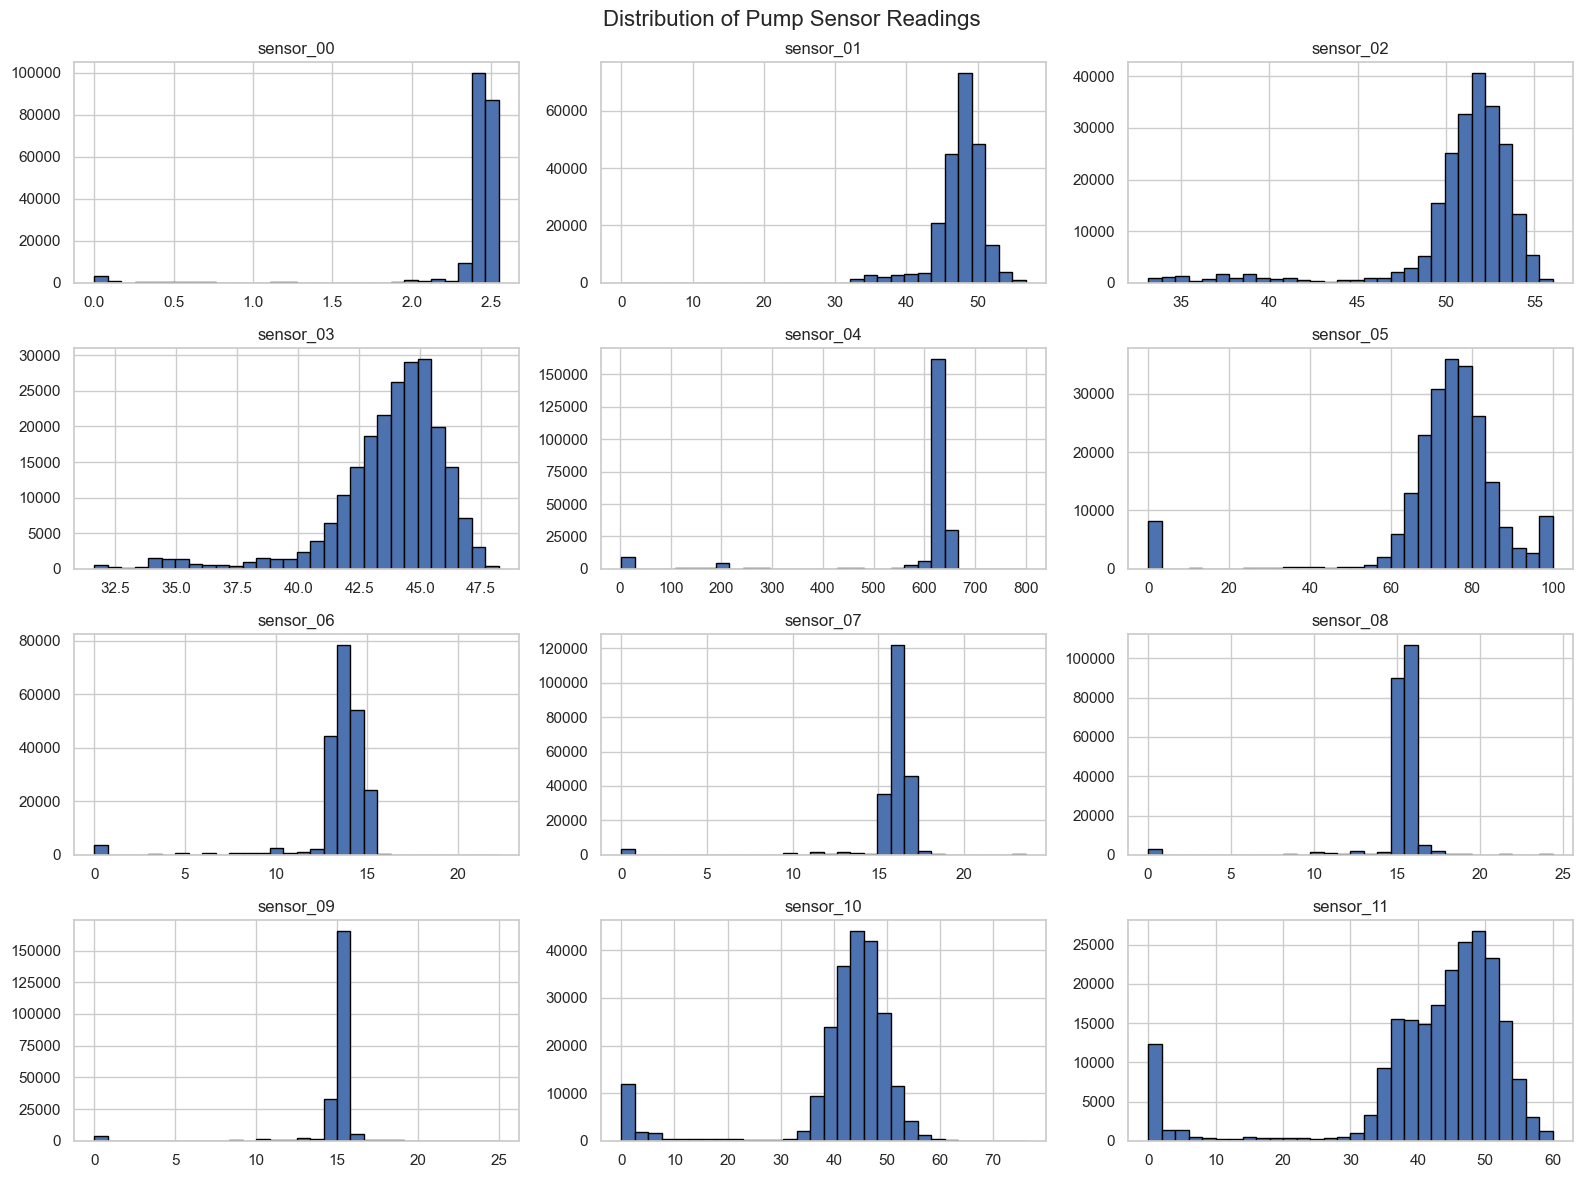

In [33]:
# ==========================================
# SENSOR DISTRIBUTION ANALYSIS
# ==========================================

if df is not None:

    sensor_columns = [
        col for col in df.columns
        if col.startswith("sensor_")
        and df[col].notna().any()
    ]

    # Select the first 12 sensors for visualization
    selected_sensors = sensor_columns[:12]

    df[selected_sensors].hist(
        figsize=(16, 12),
        bins=30,
        edgecolor="black"
    )

    plt.suptitle(
        "Distribution of Pump Sensor Readings",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

else:
    print("Dataset not loaded.")

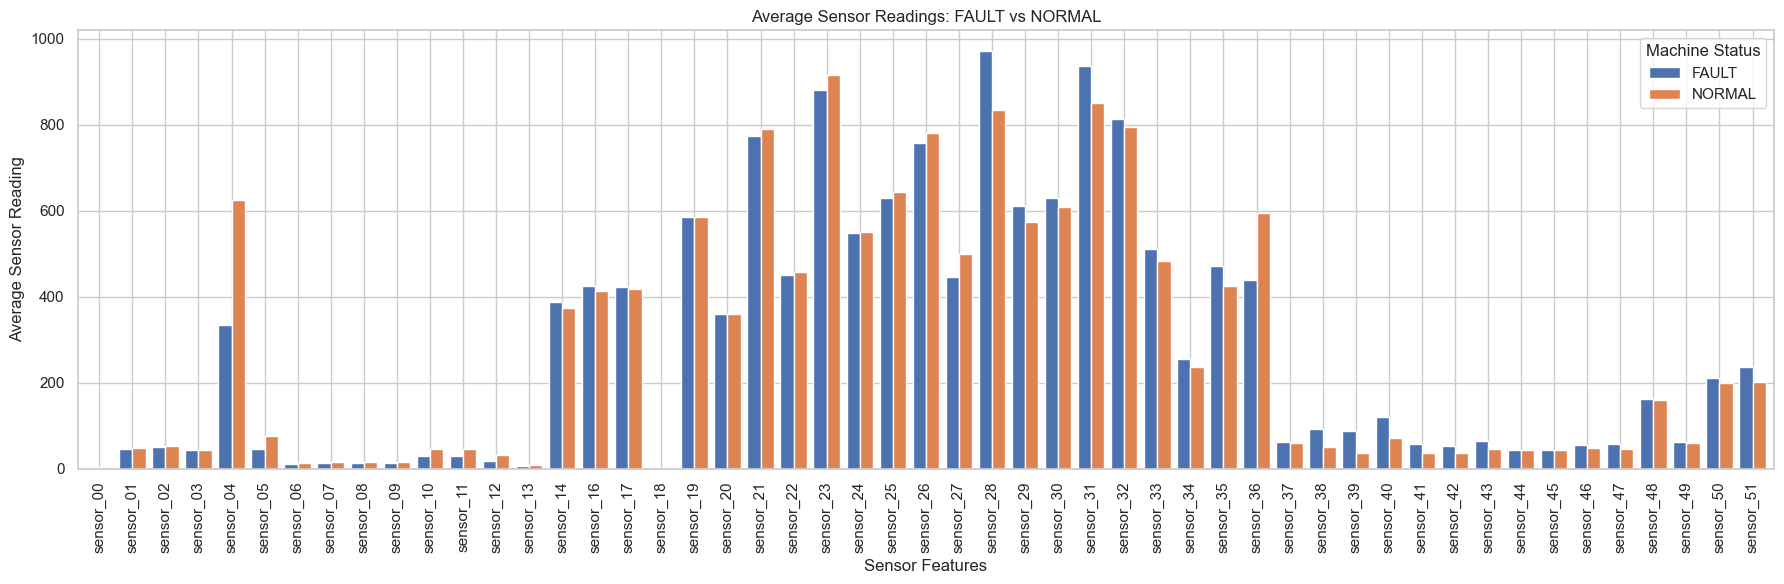

In [34]:
# ==========================================
# FAULT SENSOR DISTRIBUTION
# ==========================================

if df is not None:

    # Select records labeled BROKEN
    fault_df = df[
        df["machine_status"].str.upper() == "BROKEN"
    ].copy()

    # Select sensors that contain valid readings
    sensor_columns = [
        col for col in df.columns
        if col.startswith("sensor_")
        and df[col].notna().any()
    ]

    # Calculate average sensor readings for FAULT and NORMAL
    normal_df = df[
        df["machine_status"].str.upper() == "NORMAL"
    ]

    comparison = pd.DataFrame({
        "FAULT": fault_df[sensor_columns].mean(),
        "NORMAL": normal_df[sensor_columns].mean()
    })

    # Plot comparison
    comparison.plot(
        kind="bar",
        figsize=(18, 6),
        width=0.8
    )

    plt.title("Average Sensor Readings: FAULT vs NORMAL")
    plt.xlabel("Sensor Features")
    plt.ylabel("Average Sensor Reading")
    plt.xticks(rotation=90)
    plt.legend(title="Machine Status")
    plt.tight_layout()
    plt.show()

else:
    print("Dataset not loaded.")

In [10]:
# ==========================================
# TARGET COLUMN CONFIGURATION
# ==========================================

# Replace None with the real target column name.
# Example: TARGET_COLUMN = "condition"

TARGET_COLUMN = None

if df is not None and TARGET_COLUMN is not None:

    if TARGET_COLUMN in df.columns:
        print("Target column selected:", TARGET_COLUMN)
        print(df[TARGET_COLUMN].value_counts(dropna=False))

    else:
        print("Error: Target column does not exist.")

else:
    print("Please identify the target column first.")

Please identify the target column first.


In [35]:
# ==========================================
# FAULT DATA PREPROCESSING - INITIAL COPY
# ==========================================

if df is not None:

    # Keep the original dataset unchanged
    fault_data = df.copy()

    # Remove the original CSV index column
    if "Unnamed: 0" in fault_data.columns:
        fault_data = fault_data.drop(columns=["Unnamed: 0"])

    # Remove completely empty sensor columns
    empty_columns = [
        col for col in fault_data.columns
        if col.startswith("sensor_")
        and fault_data[col].isna().all()
    ]

    fault_data = fault_data.drop(columns=empty_columns)

    print("Initial preprocessing completed!")
    print("Removed empty columns:", empty_columns)
    print("Original shape:", df.shape)
    print("Preprocessed shape:", fault_data.shape)

    display(fault_data.head())

else:
    print("Dataset not loaded.")

Initial preprocessing completed!
Removed empty columns: ['sensor_15']
Original shape: (220320, 55)
Preprocessed shape: (220320, 53)


,timestamp,sensor_00,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,sensor_08,...,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,machine_status
0,2018-04-01 00:00:00,2.465394,47.09201,53.2118,46.310760,634.3750,76.45975,13.41146,16.13136,15.56713,...,41.92708,39.641200,65.68287,50.92593,38.194440,157.9861,67.70834,243.0556,201.3889,NORMAL
1,2018-04-01 00:01:00,2.465394,47.09201,53.2118,46.310760,634.3750,76.45975,13.41146,16.13136,15.56713,...,41.92708,39.641200,65.68287,50.92593,38.194440,157.9861,67.70834,243.0556,201.3889,NORMAL
2,2018-04-01 00:02:00,2.444734,47.35243,53.2118,46.397570,638.8889,73.54598,13.32465,16.03733,15.61777,...,41.66666,39.351852,65.39352,51.21528,38.194443,155.9606,67.12963,241.3194,203.7037,NORMAL
3,2018-04-01 00:03:00,2.460474,47.09201,53.1684,46.397568,628.1250,76.98898,13.31742,16.24711,15.69734,...,40.88541,39.062500,64.81481,51.21528,38.194440,155.9606,66.84028,240.4514,203.1250,NORMAL
4,2018-04-01 00:04:00,2.445718,47.13541,53.2118,46.397568,636.4583,76.58897,13.35359,16.21094,15.69734,...,41.40625,38.773150,65.10416,51.79398,38.773150,158.2755,66.55093,242.1875,201.3889,NORMAL


In [36]:
# ==========================================
# MISSING VALUES AFTER INITIAL PREPROCESSING
# ==========================================

if "fault_data" in globals():

    missing_values = fault_data.isnull().sum()

    missing_summary = pd.DataFrame({
        "Missing Values": missing_values,
        "Missing Percentage": (
            missing_values / len(fault_data)
        ) * 100
    })

    missing_summary = missing_summary[
        missing_summary["Missing Values"] > 0
    ].sort_values(
        by="Missing Percentage",
        ascending=False
    )

    print("Remaining Missing Values:")
    display(missing_summary)

    print("Total missing values:",
          fault_data.isnull().sum().sum())

else:
    print("Run the initial preprocessing cell first.")

Remaining Missing Values:


,Missing Values,Missing Percentage
sensor_50,77017,34.956881
sensor_51,15383,6.982117
sensor_00,10208,4.633261
sensor_07,5451,2.474129
sensor_08,5107,2.317992
sensor_06,4798,2.177741
sensor_09,4595,2.085603
sensor_01,369,0.167484
sensor_30,261,0.118464
sensor_29,72,0.032680


Total missing values: 124254


In [37]:
# ==========================================
# MISSING VALUES BY MACHINE STATUS
# ==========================================

if "fault_data" in globals():

    sensor_columns = [
        col for col in fault_data.columns
        if col.startswith("sensor_")
    ]

    missing_by_status = (
        fault_data
        .groupby("machine_status")[sensor_columns]
        .apply(lambda group: group.isnull().sum())
        .T
    )

    print("Missing sensor readings by machine status:")
    display(missing_by_status)

    # Inspect missing values in the seven FAULT records
    fault_records = fault_data[
        fault_data["machine_status"] == "BROKEN"
    ]

    print("\nFAULT records:", len(fault_records))
    print(
        "Missing values in FAULT records:",
        fault_records[sensor_columns].isnull().sum().sum()
    )

    display(
        fault_records[
            ["timestamp"] + sensor_columns
        ].loc[:, lambda x: x.isnull().any(axis=0) | (x.columns == "timestamp")]
    )

else:
    print("Run the initial preprocessing cell first.")

Missing sensor readings by machine status:


machine_status,BROKEN,NORMAL,RECOVERING
sensor_00,0,14,10194
sensor_01,0,339,30
sensor_02,0,14,5
sensor_03,0,14,5
sensor_04,0,14,5
sensor_05,0,14,5
sensor_06,0,14,4784
sensor_07,0,14,5437
sensor_08,0,14,5093
sensor_09,0,14,4581



FAULT records: 7
Missing values in FAULT records: 2


,timestamp,sensor_50,sensor_51
17155,2018-04-12 21:55:00,401.909700,324.6528
24510,2018-04-18 00:30:00,177.662000,183.7384
69318,2018-05-19 03:18:00,246.238400,257.5231
77790,2018-05-25 00:30:00,220.196800,267.3611
128040,2018-06-28 22:00:00,32.407406,NaN
141131,2018-07-08 00:11:00,192.129600,174.7685
166440,2018-07-25 14:00:00,NaN,205.7292


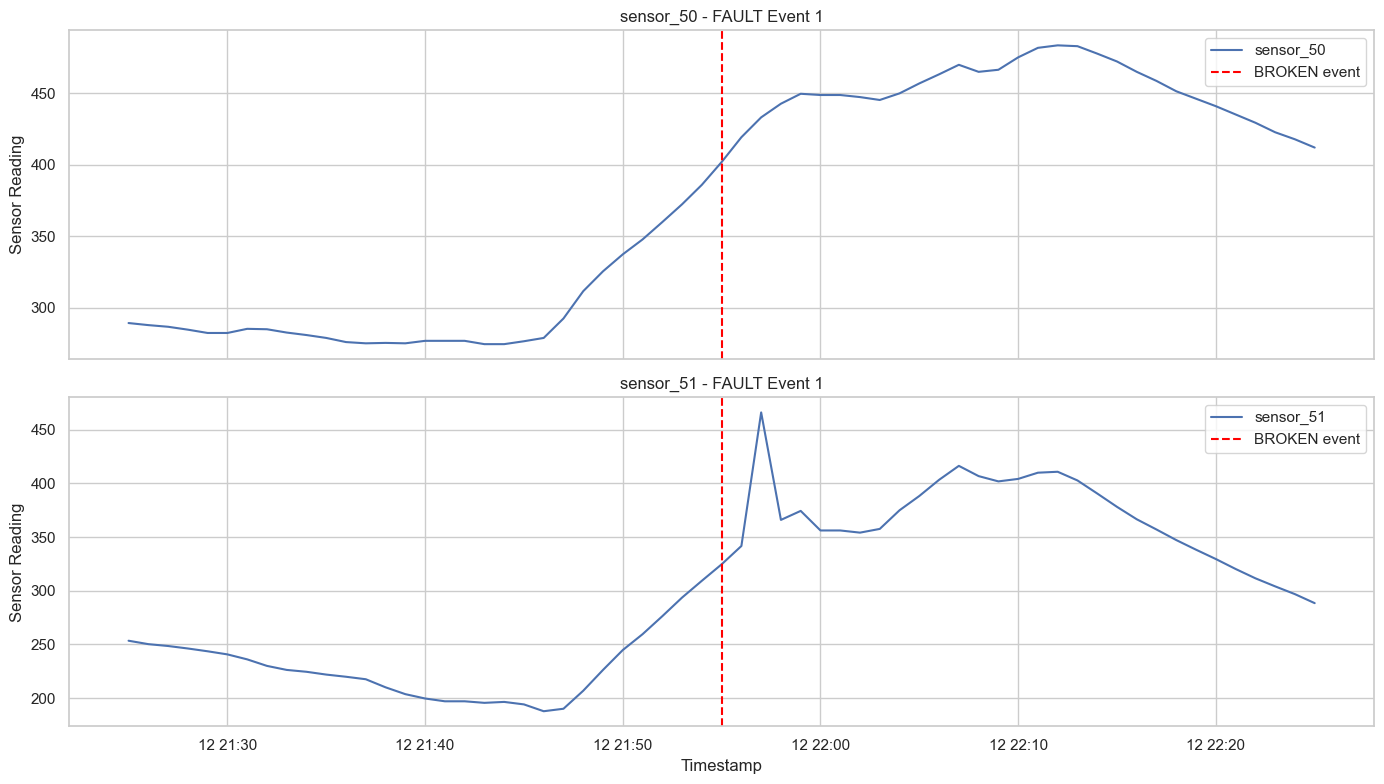

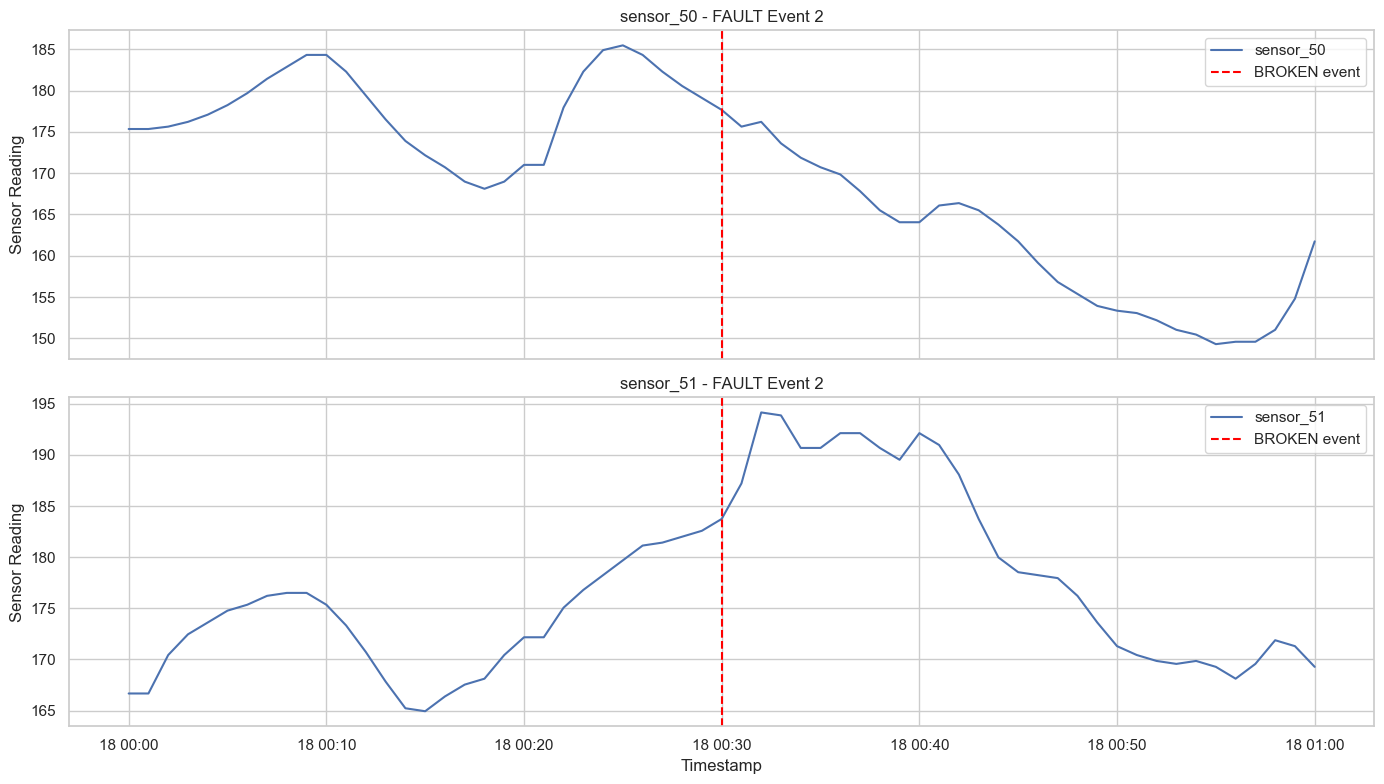

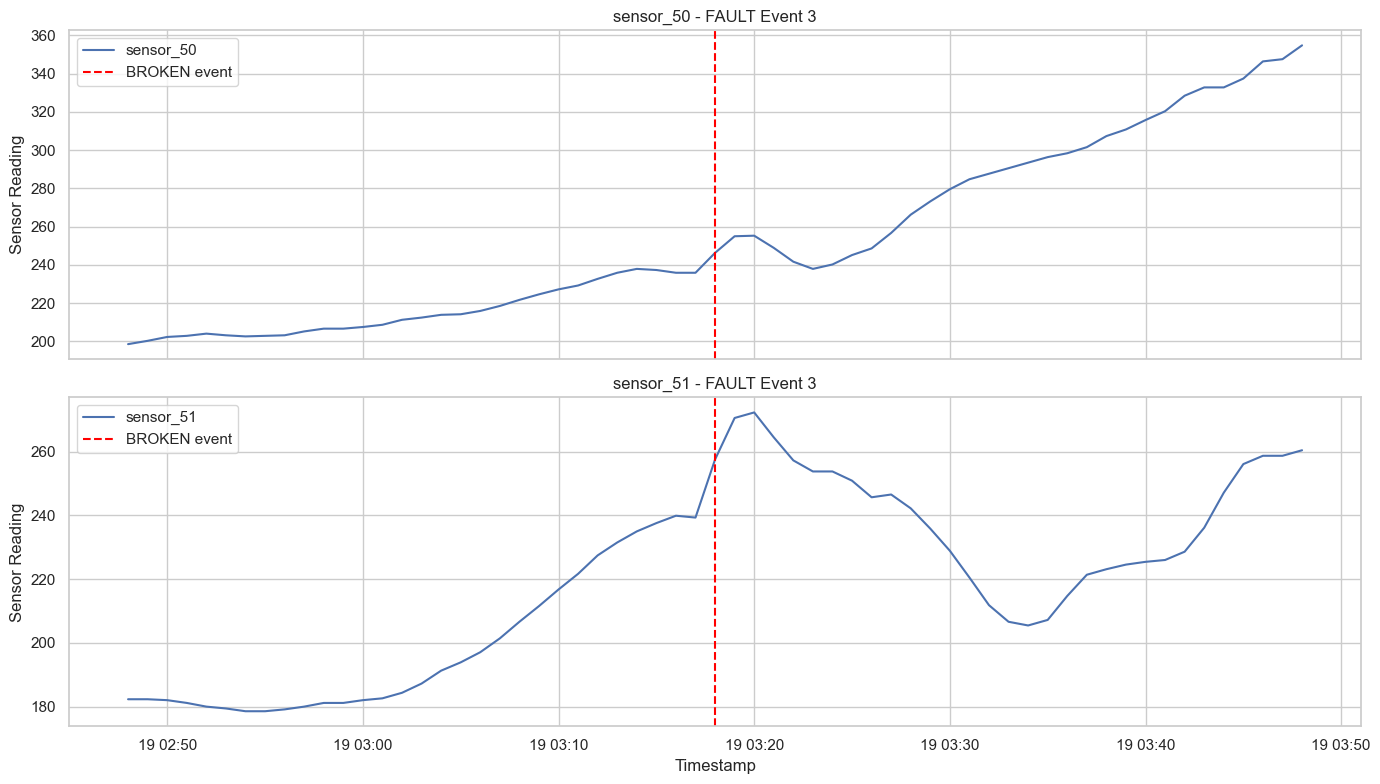

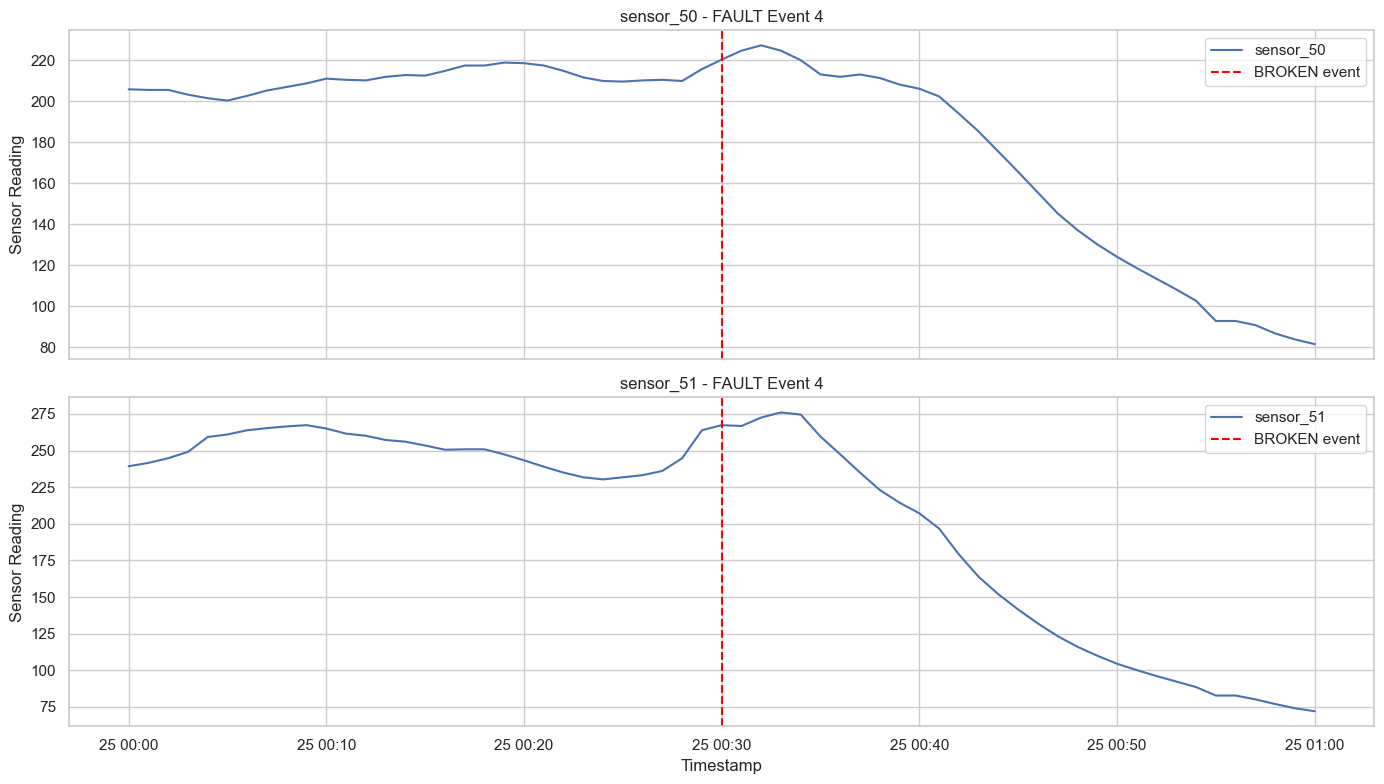

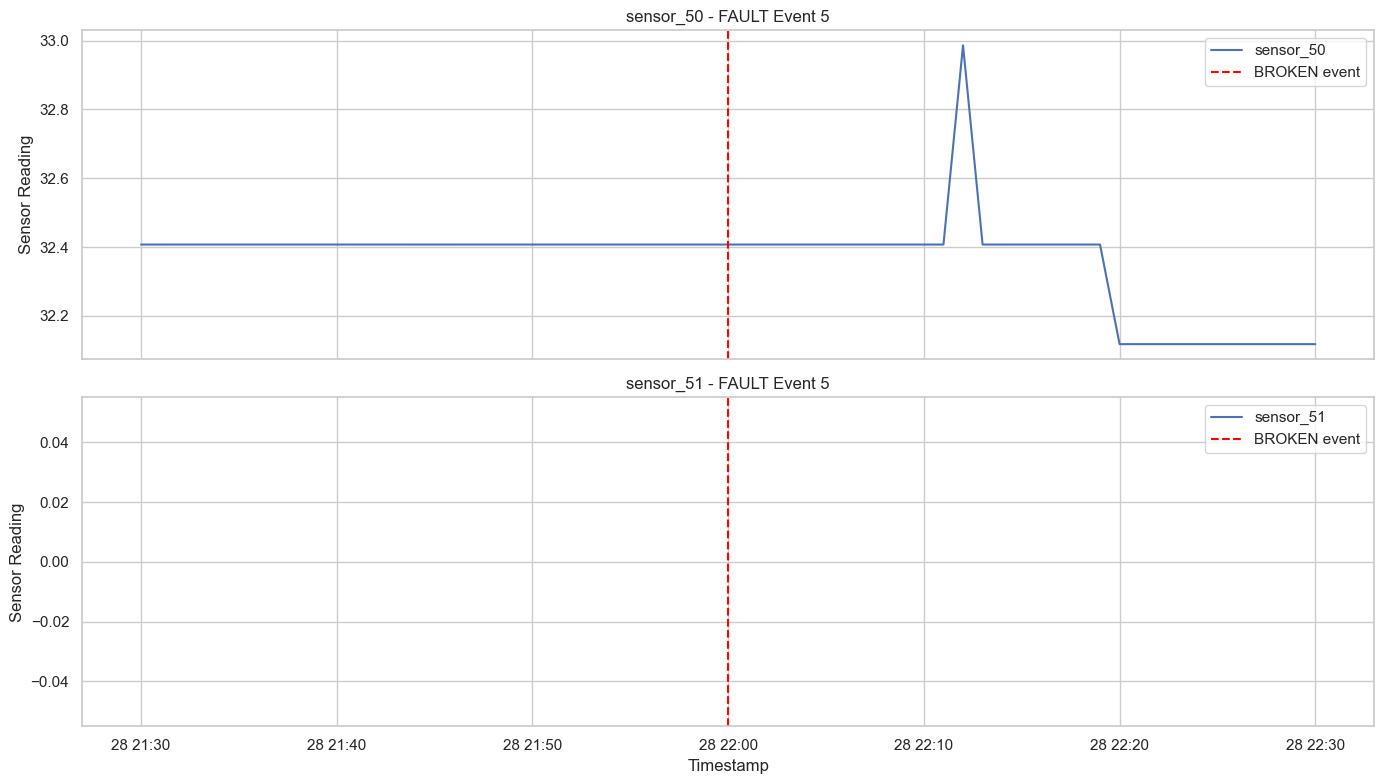

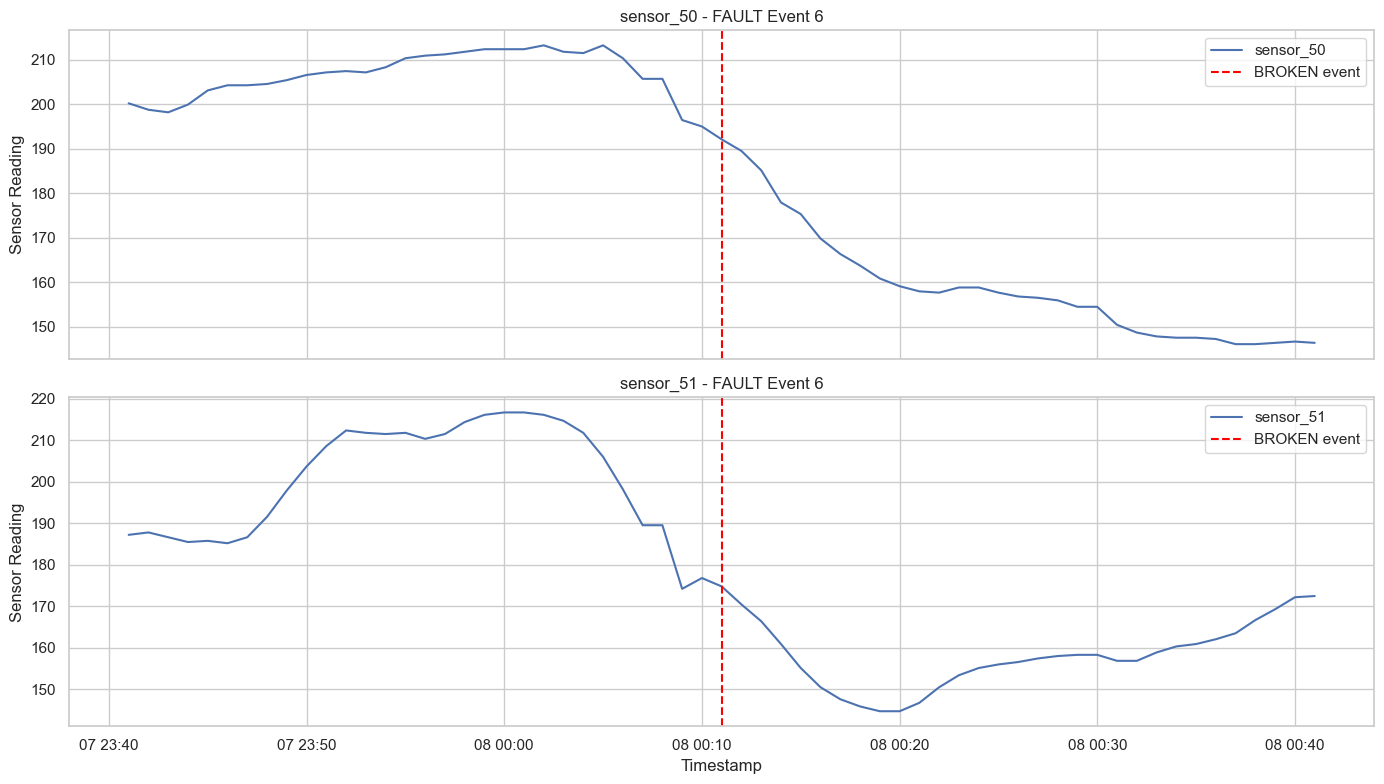

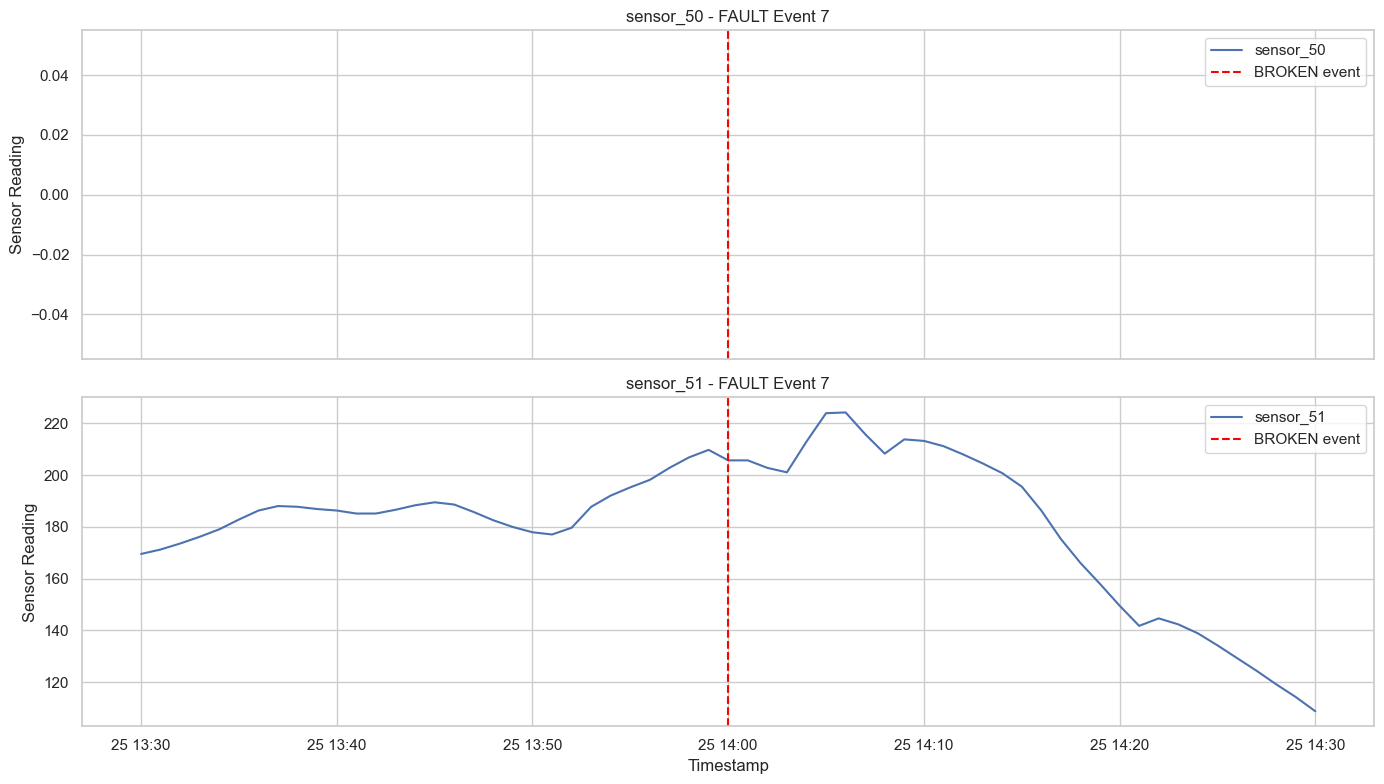

In [38]:
# ==========================================
# SENSOR BEHAVIOR AROUND FAULT EVENTS
# ==========================================

if df is not None:

    # Convert timestamps to datetime
    fault_data["timestamp"] = pd.to_datetime(
        fault_data["timestamp"]
    )

    # Sort records by time
    fault_data = fault_data.sort_values("timestamp")

    # Get all BROKEN event timestamps
    fault_events = fault_data[
        fault_data["machine_status"] == "BROKEN"
    ]["timestamp"]

    # Sensors to investigate
    selected_sensors = ["sensor_50", "sensor_51"]

    # Plot readings around each FAULT event
    for event_number, event_time in enumerate(fault_events, start=1):

        start_time = event_time - pd.Timedelta(minutes=30)
        end_time = event_time + pd.Timedelta(minutes=30)

        window = fault_data[
            (fault_data["timestamp"] >= start_time) &
            (fault_data["timestamp"] <= end_time)
        ]

        fig, axes = plt.subplots(
            2, 1,
            figsize=(14, 8),
            sharex=True
        )

        for i, sensor in enumerate(selected_sensors):

            axes[i].plot(
                window["timestamp"],
                window[sensor],
                label=sensor
            )

            axes[i].axvline(
                event_time,
                color="red",
                linestyle="--",
                label="BROKEN event"
            )

            axes[i].set_title(
                f"{sensor} - FAULT Event {event_number}"
            )

            axes[i].set_ylabel("Sensor Reading")
            axes[i].legend()
            axes[i].grid(True)

        axes[1].set_xlabel("Timestamp")

        plt.tight_layout()
        plt.show()

else:
    print("Dataset not loaded.")

In [11]:
# ==========================================
# CLASS DISTRIBUTION ANALYSIS
# ==========================================

if df is not None and TARGET_COLUMN in df.columns:

    class_counts = df[TARGET_COLUMN].value_counts(
        dropna=False
    )

    print("Class distribution:")
    display(class_counts.to_frame(name="Record Count"))

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x=TARGET_COLUMN,
        order=df[TARGET_COLUMN].value_counts().index
    )

    plt.title("Pump Condition Distribution")
    plt.xlabel("Pump Condition")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

else:
    print("Configure the target column first.")

Configure the target column first.


In [39]:
# ==========================================
# FAULT EVENT SENSOR SUMMARY
# ==========================================

sensor_columns = ["sensor_50", "sensor_51"]

for event_number, event_time in enumerate(fault_events, start=1):

    start_time = event_time - pd.Timedelta(minutes=30)
    end_time = event_time + pd.Timedelta(minutes=30)

    window = fault_data[
        (fault_data["timestamp"] >= start_time) &
        (fault_data["timestamp"] <= end_time)
    ]

    print(f"\nFAULT EVENT {event_number}")
    print("Timestamp:", event_time)

    display(
        window[sensor_columns].describe().round(3)
    )


FAULT EVENT 1
Timestamp: 2018-04-12 21:55:00


,sensor_50,sensor_51
count,61.000,61.000
mean,374.720,298.255
std,82.077,78.173
min,274.595,187.789
25%,282.697,226.273
50%,401.910,296.875
75%,449.653,366.030
max,483.507,466.146



FAULT EVENT 2
Timestamp: 2018-04-18 00:30:00


,sensor_50,sensor_51
count,61.000,61.000
mean,169.385,176.965
std,11.000,8.434
min,149.306,164.931
25%,161.748,170.428
50%,171.007,175.347
75%,177.951,182.002
max,185.474,194.155



FAULT EVENT 3
Timestamp: 2018-05-19 03:18:00


,sensor_50,sensor_51
count,61.000,61.000
mean,253.079,219.082
std,46.461,29.234
min,198.495,178.530
25%,212.384,187.211
50%,237.847,221.644
75%,290.509,242.188
max,354.745,272.280


... (4 outputs left out)


FAULT EVENT 6
Timestamp: 2018-07-08 00:11:00


,sensor_50,sensor_51
count,61.000,61.000
mean,182.477,179.137
std,25.979,23.994
min,146.123,144.676
25%,156.829,157.986
50%,192.130,174.190
75%,207.176,203.704
max,213.252,216.724



FAULT EVENT 7
Timestamp: 2018-07-25 14:00:00


,sensor_50,sensor_51
count,0.0,61.000
mean,NaN,181.462
std,NaN,27.875
min,NaN,108.796
25%,NaN,173.611
50%,NaN,186.343
75%,NaN,202.836
max,NaN,224.248


In [40]:
# ==========================================
# SENSOR ANALYSIS: 30 MINUTES BEFORE FAULT
# ==========================================

pre_fault_results = []

for event_number, event_time in enumerate(fault_events, start=1):

    start_time = event_time - pd.Timedelta(minutes=30)

    # Only observations strictly before the failure
    window = fault_data[
        (fault_data["timestamp"] >= start_time) &
        (fault_data["timestamp"] < event_time)
    ]

    for sensor in ["sensor_50", "sensor_51"]:

        pre_fault_results.append({
            "Event": event_number,
            "Fault Timestamp": event_time,
            "Sensor": sensor,
            "Count": window[sensor].count(),
            "Mean": window[sensor].mean(),
            "Std": window[sensor].std(),
            "Minimum": window[sensor].min(),
            "Maximum": window[sensor].max()
        })

pre_fault_summary = pd.DataFrame(pre_fault_results)

display(pre_fault_summary.round(3))

,Event,Fault Timestamp,Sensor,Count,Mean,Std,Minimum,Maximum
0,1,2018-04-12 21:55:00,sensor_50,30,296.566,31.908,274.595,385.995
1,1,2018-04-12 21:55:00,sensor_51,30,228.260,30.774,187.789,309.317
2,2,2018-04-18 00:30:00,sensor_50,30,177.681,5.290,168.113,185.474
3,2,2018-04-18 00:30:00,sensor_51,30,173.341,5.243,164.931,182.581
4,3,2018-05-19 03:18:00,sensor_50,30,215.249,13.117,198.495,237.847
5,3,2018-05-19 03:18:00,sensor_51,30,198.409,22.068,178.530,239.873
6,4,2018-05-25 00:30:00,sensor_50,30,210.262,5.148,200.232,218.750
7,4,2018-05-25 00:30:00,sensor_51,30,250.019,11.936,230.324,267.361
8,5,2018-06-28 22:00:00,sensor_50,30,32.407,0.000,32.407,32.407
9,5,2018-06-28 22:00:00,sensor_51,0,NaN,NaN,NaN,NaN


In [41]:
# ==========================================
# COMPARE PRE-FAULT SENSOR READINGS
# WITH NORMAL OPERATION
# ==========================================

sensor_columns = [
    col for col in fault_data.columns
    if col.startswith("sensor_")
]

normal_data = fault_data[
    fault_data["machine_status"] == "NORMAL"
]

normal_mean = normal_data[sensor_columns].mean()
normal_std = normal_data[sensor_columns].std()

results = []

for event_number, event_time in enumerate(fault_events, start=1):

    start_time = event_time - pd.Timedelta(minutes=30)

    # Use only readings BEFORE the fault
    window = fault_data[
        (fault_data["timestamp"] >= start_time) &
        (fault_data["timestamp"] < event_time)
    ]

    fault_mean = window[sensor_columns].mean()

    z_scores = (
        (fault_mean - normal_mean) / normal_std
    ).abs()

    event_results = pd.DataFrame({
        "Sensor": sensor_columns,
        "Pre-FAULT Mean": fault_mean.values,
        "NORMAL Mean": normal_mean.values,
        "Absolute Z-Score": z_scores.values
    })

    event_results = event_results.dropna()

    event_results = event_results.sort_values(
        "Absolute Z-Score",
        ascending=False
    )

    print(f"\n========== FAULT EVENT {event_number} ==========")
    display(event_results.head(10).round(3))


========== FAULT EVENT 1 ==========


,Sensor,Pre-FAULT Mean,NORMAL Mean,Absolute Z-Score
4,sensor_04,444.635,625.673,3.562
49,sensor_50,296.566,199.022,2.149
1,sensor_01,52.176,48.180,1.784
47,sensor_48,282.658,158.886,1.573
36,sensor_37,117.961,60.109,1.527
48,sensor_49,83.063,58.570,1.365
0,sensor_00,2.155,2.420,1.097
35,sensor_36,302.412,594.513,0.995
27,sensor_28,1142.534,834.805,0.975
6,sensor_06,13.077,13.865,0.911



========== FAULT EVENT 2 ==========


,Sensor,Pre-FAULT Mean,NORMAL Mean,Absolute Z-Score
4,sensor_04,397.712,625.673,4.485
1,sensor_01,43.552,48.180,2.066
2,sensor_02,47.786,51.637,2.050
3,sensor_03,41.437,44.167,1.637
0,sensor_00,2.032,2.420,1.601
47,sensor_48,57.051,158.886,1.294
8,sensor_08,16.223,15.478,1.266
9,sensor_09,15.703,15.087,1.076
45,sensor_46,33.883,48.859,1.020
46,sensor_47,34.915,45.047,1.014



========== FAULT EVENT 3 ==========


,Sensor,Pre-FAULT Mean,NORMAL Mean,Absolute Z-Score
12,sensor_12,23.436,31.172,1.137
35,sensor_36,284.426,594.513,1.056
27,sensor_28,1151.229,834.805,1.002
43,sensor_44,34.742,43.381,0.773
28,sensor_29,750.322,573.008,0.770
32,sensor_33,599.680,482.223,0.762
5,sensor_05,82.517,75.390,0.760
33,sensor_34,171.630,235.899,0.713
44,sensor_45,35.301,43.785,0.682
2,sensor_02,52.750,51.637,0.593


... (4 outputs left out)


========== FAULT EVENT 6 ==========


,Sensor,Pre-FAULT Mean,NORMAL Mean,Absolute Z-Score
7,sensor_07,12.397,16.166,6.278
9,sensor_09,11.570,15.087,6.137
8,sensor_08,12.049,15.478,5.826
6,sensor_06,11.196,13.865,3.086
0,sensor_00,1.970,2.420,1.856
13,sensor_13,16.945,7.573,1.364
1,sensor_01,45.365,48.180,1.257
34,sensor_35,587.722,423.701,1.141
37,sensor_38,58.594,50.664,1.035
3,sensor_03,45.648,44.167,0.888



========== FAULT EVENT 7 ==========


,Sensor,Pre-FAULT Mean,NORMAL Mean,Absolute Z-Score
4,sensor_04,485.296,625.673,2.762
45,sensor_46,66.155,48.859,1.178
33,sensor_34,339.212,235.899,1.145
1,sensor_01,45.825,48.180,1.051
43,sensor_44,55.015,43.381,1.041
39,sensor_40,88.594,70.971,0.985
44,sensor_45,55.739,43.785,0.961
31,sensor_32,1003.701,794.855,0.798
25,sensor_26,980.984,781.439,0.788
2,sensor_02,53.028,51.637,0.741


In [42]:
# ==========================================
# COUNT SENSOR FREQUENCY ACROSS FAULT EVENTS
# ==========================================

sensor_frequency = {}

for event_number, event_time in enumerate(fault_events, start=1):

    start_time = event_time - pd.Timedelta(minutes=30)

    window = fault_data[
        (fault_data["timestamp"] >= start_time) &
        (fault_data["timestamp"] < event_time)
    ]

    fault_mean = window[sensor_columns].mean()

    z_scores = (
        (fault_mean - normal_mean) / normal_std
    ).abs()

    top_sensors = z_scores.dropna().nlargest(10).index

    for sensor in top_sensors:
        sensor_frequency[sensor] = (
            sensor_frequency.get(sensor, 0) + 1
        )

frequency_df = pd.DataFrame(
    list(sensor_frequency.items()),
    columns=["Sensor", "Number of Events in Top 10"]
)

frequency_df = frequency_df.sort_values(
    "Number of Events in Top 10",
    ascending=False
)

display(frequency_df)

,Sensor,Number of Events in Top 10
2,sensor_01,5
0,sensor_04,4
10,sensor_02,4
6,sensor_00,4
23,sensor_38,3
14,sensor_46,3
7,sensor_36,3
1,sensor_50,2
3,sensor_48,2
9,sensor_06,2


### FAULT Sensor Analysis – Key Findings

The analysis examined the 30-minute periods before seven recorded FAULT events and compared their sensor readings with the overall NORMAL operating averages.

The most frequently different sensors were:

- `sensor_01`: appeared in the top 10 for 5 out of 7 events.
- `sensor_04`: appeared in the top 10 for 4 out of 7 events.
- `sensor_02`: appeared in the top 10 for 4 out of 7 events.
- `sensor_00`: appeared in the top 10 for 4 out of 7 events.
- `sensor_38`, `sensor_46`, and `sensor_36`: appeared in the top 10 for 3 out of 7 events.

**Conclusion:** Sensor readings show different patterns before the recorded FAULT events. Sensor_01 was the most frequently different from the overall NORMAL average.

**Limitations:** Only seven BROKEN observations are available. These results are exploratory and cannot establish reliable failure-prediction patterns. The sensor differences may also be influenced by operating conditions. Further data and validation are required before selecting final model features.

In [12]:
# ==========================================
# CLASS PERCENTAGE ANALYSIS
# ==========================================

if df is not None and TARGET_COLUMN in df.columns:

    class_percentages = (
        df[TARGET_COLUMN]
        .value_counts(normalize=True, dropna=False)
        * 100
    )

    display(
        class_percentages.to_frame(
            name="Percentage (%)"
        ).round(2)
    )

else:
    print("Target column not configured.")

Target column not configured.


In [43]:
from pathlib import Path
import sys

sys.path.append(str(FAULT_DIR / "src"))

from fault_preprocessing import preprocess_fault_data

fault_final = preprocess_fault_data(df)

display(fault_final.head())
print(fault_final["machine_status"].value_counts())

FAULT dataset shape: (7, 53)
FAULT records: 7
Removed completely empty columns: ['sensor_15']


,timestamp,sensor_00,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,sensor_06,sensor_07,sensor_08,...,sensor_43,sensor_44,sensor_45,sensor_46,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,machine_status
17155,2018-04-12 21:55:00,0.000000,53.34201,52.821180,43.402775,202.526031,49.79289,3.219039,16.89091,16.86921,...,50.78125,50.92593,51.215280,50.636570,46.006940,409.143500,121.527800,401.909700,324.6528,FAULT
24510,2018-04-18 00:30:00,1.093982,42.53472,47.699650,41.449650,206.038757,60.30106,12.304690,15.15480,14.18547,...,42.70833,34.72222,31.539350,34.432870,33.275460,59.895830,44.560180,177.662000,183.7384,FAULT
69318,2018-05-19 03:18:00,2.258796,47.26563,52.734370,43.446178,200.115738,66.14643,13.592300,15.91435,15.14757,...,39.06250,35.01157,37.905090,39.062500,45.428240,144.675900,49.768520,246.238400,257.5231,FAULT
77790,2018-05-25 00:30:00,2.321759,47.48264,51.475693,42.795135,612.152800,67.30158,14.062500,16.60880,15.94329,...,202.34370,65.68287,57.870370,127.893500,153.935200,155.381900,65.682870,220.196800,267.3611,FAULT
128040,2018-06-28 22:00:00,0.364005,40.19097,45.225690,40.190971,201.368622,0.00000,11.335360,15.27054,15.18374,...,32.29166,28.06713,28.067129,29.513889,29.224537,29.224537,29.513889,32.407406,NaN,FAULT


machine_status
FAULT    7
Name: count, dtype: int64


In [44]:
from pathlib import Path

OUTPUT_DIR = FAULT_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR)


Output directory: d:\ml asignment\machine-learning\fault\outputs


In [13]:
# ==========================================
# EXTRACT FAULT RECORDS
# ==========================================

if df is not None and TARGET_COLUMN in df.columns:

    normalized_labels = (
        df[TARGET_COLUMN]
        .astype("string")
        .str.strip()
        .str.upper()
    )

    fault_df = df[
        normalized_labels == "FAULT"
    ].copy()

    print("FAULT ANALYSIS")
    print("=" * 40)

    print("Total original records:", len(df))
    print("Total FAULT records:", len(fault_df))

    if not fault_df.empty:
        display(fault_df.head())
    else:
        print("No records labeled FAULT were found.")

else:
    fault_df = None
    print("Dataset or target column is unavailable.")

Dataset or target column is unavailable.


In [45]:
fault_final.to_csv(
    OUTPUT_DIR / "fault_records.csv",
    index=False
)

print("FAULT dataset saved successfully!")

FAULT dataset saved successfully!


In [14]:
# ==========================================
# FAULT SENSOR STATISTICS
# ==========================================

if fault_df is not None and not fault_df.empty:

    numeric_features = fault_df.select_dtypes(
        include=np.number
    ).columns.tolist()

    numeric_features = [
        col for col in numeric_features
        if col != TARGET_COLUMN
    ]

    display(fault_df[numeric_features].describe())

else:
    print("No FAULT records available.")

No FAULT records available.


In [46]:
frequency_df.to_csv(
    OUTPUT_DIR / "fault_sensor_frequency.csv",
    index=False
)

print("Sensor frequency results saved!")

Sensor frequency results saved!


In [15]:
# ==========================================
# FAULT SENSOR DISTRIBUTION
# ==========================================

if fault_df is not None and not fault_df.empty:

    numeric_features = fault_df.select_dtypes(
        include=np.number
    ).columns.tolist()

    numeric_features = [
        col for col in numeric_features
        if col != TARGET_COLUMN
    ]

    if numeric_features:

        fault_df[numeric_features].hist(
            figsize=(15, 10),
            bins=25
        )

        plt.suptitle(
            "Distribution of Sensor Measurements in FAULT Records"
        )

        plt.tight_layout()
        plt.show()

    else:
        print("No numerical sensor features found.")

else:
    print("FAULT data unavailable.")

FAULT data unavailable.


In [47]:
plt.savefig(
    OUTPUT_DIR / "fault_sensor_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

In [16]:
# ==========================================
# SENSOR CORRELATION ANALYSIS
# ==========================================

if fault_df is not None and not fault_df.empty:

    numeric_features = fault_df.select_dtypes(
        include=np.number
    ).columns.tolist()

    numeric_features = [
        col for col in numeric_features
        if col != TARGET_COLUMN
    ]

    if len(numeric_features) >= 2:

        correlation = fault_df[numeric_features].corr()

        plt.figure(figsize=(12, 8))

        sns.heatmap(
            correlation,
            annot=True,
            cmap="coolwarm",
            fmt=".2f"
        )

        plt.title("FAULT Sensor Feature Correlation")
        plt.tight_layout()
        plt.show()

    else:
        print("At least two numerical features are needed.")

else:
    print("FAULT data unavailable.")

FAULT data unavailable.


In [48]:
plt.savefig(
    OUTPUT_DIR / "fault_sensor_comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.close()

In [17]:
# ==========================================
# OUTLIER ANALYSIS
# ==========================================

if fault_df is not None and not fault_df.empty:

    numeric_features = fault_df.select_dtypes(
        include=np.number
    ).columns.tolist()

    numeric_features = [
        col for col in numeric_features
        if col != TARGET_COLUMN
    ]

    for feature in numeric_features:

        plt.figure(figsize=(8, 4))

        sns.boxplot(data=fault_df, x=feature)

        plt.title(f"FAULT Outlier Analysis: {feature}")
        plt.tight_layout()
        plt.show()

else:
    print("FAULT data unavailable.")

FAULT data unavailable.


In [49]:
fault_final = preprocess_fault_data(df)

print("\nFinal verification:")
print("Records:", len(fault_final))
print("Labels:")
print(fault_final["machine_status"].value_counts())

print("Original dataset unchanged:", len(df) == 220320)

FAULT dataset shape: (7, 53)
FAULT records: 7
Removed completely empty columns: ['sensor_15']

Final verification:
Records: 7
Labels:
machine_status
FAULT    7
Name: count, dtype: int64
Original dataset unchanged: True


In [18]:
# ==========================================
# OUTLIER ANALYSIS
# ==========================================

if fault_df is not None and not fault_df.empty:

    numeric_features = fault_df.select_dtypes(
        include=np.number
    ).columns.tolist()

    numeric_features = [
        col for col in numeric_features
        if col != TARGET_COLUMN
    ]

    for feature in numeric_features:

        plt.figure(figsize=(8, 4))

        sns.boxplot(data=fault_df, x=feature)

        plt.title(f"FAULT Outlier Analysis: {feature}")
        plt.tight_layout()
        plt.show()

else:
    print("FAULT data unavailable.")

FAULT data unavailable.


In [19]:
# ==========================================
# FAULT DATA PREPARATION
# ==========================================

if fault_df is not None and not fault_df.empty:

    fault_processed = fault_df.copy()

    original_count = len(fault_processed)

    # Remove exact duplicate records
    fault_processed = fault_processed.drop_duplicates()

    removed_duplicates = (
        original_count - len(fault_processed)
    )

    print("FAULT preprocessing inspection")
    print("--------------------------------")
    print("Original FAULT records:", original_count)
    print("Removed exact duplicates:", removed_duplicates)
    print("Remaining FAULT records:", len(fault_processed))

    print("\nRemaining missing values:")
    display(fault_processed.isnull().sum())

else:
    fault_processed = None
    print("No FAULT records available.")

No FAULT records available.


In [20]:
# ==========================================
# FEATURE TYPE IDENTIFICATION
# ==========================================

if fault_processed is not None:

    numerical_features = (
        fault_processed
        .select_dtypes(include=np.number)
        .columns.tolist()
    )

    categorical_features = (
        fault_processed
        .select_dtypes(exclude=np.number)
        .columns.tolist()
    )

    numerical_features = [
        col for col in numerical_features
        if col != TARGET_COLUMN
    ]

    categorical_features = [
        col for col in categorical_features
        if col != TARGET_COLUMN
    ]

    print("Numerical features:")
    print(numerical_features)

    print("\nCategorical features:")
    print(categorical_features)

else:
    print("FAULT data unavailable.")

FAULT data unavailable.


In [21]:
# ==========================================
# SAVE FAULT DATASET
# ==========================================

if fault_processed is not None and not fault_processed.empty:

    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    fault_output = OUTPUT_DIR / "fault_records.csv"

    fault_processed.to_csv(
        fault_output,
        index=False
    )

    print("FAULT dataset exported successfully!")
    print("Saved file:", fault_output)

else:
    print("No FAULT records available for export.")

No FAULT records available for export.


In [22]:
# ==========================================
# FINAL FAULT ANALYSIS REPORT
# ==========================================

print("=" * 55)
print("PUMP CONDITION CLASSIFICATION")
print("FAULT ANALYSIS REPORT")
print("=" * 55)

if df is not None:

    print("Original dataset records:", len(df))

    if TARGET_COLUMN in df.columns:

        print(
            "Total FAULT records:",
            len(fault_df)
        )

        if len(df) > 0:
            fault_percentage = (
                len(fault_df) / len(df)
            ) * 100

            print(
                "FAULT percentage:",
                round(fault_percentage, 2),
                "%"
            )

    if fault_processed is not None:

        print(
            "Processed FAULT records:",
            len(fault_processed)
        )

        print("Output directory:", OUTPUT_DIR)

else:
    print("Original dataset not loaded.")

print("\nResponsible component: FAULT")
print("Project: Pump Condition Classification")

PUMP CONDITION CLASSIFICATION
FAULT ANALYSIS REPORT
Original dataset not loaded.

Responsible component: FAULT
Project: Pump Condition Classification
